In [16]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

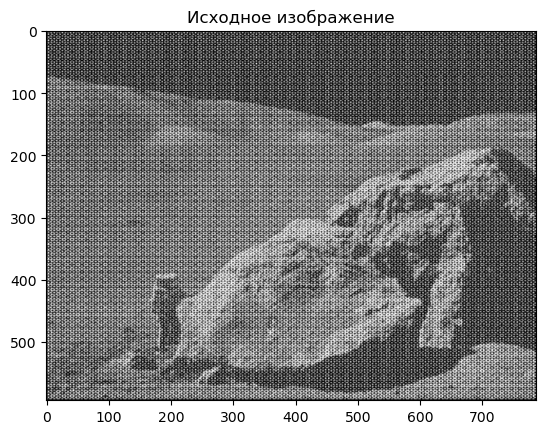

In [17]:
image = cv2.imread('periodic.JPG', cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError('Изображение periodic_noise.jpg не найдено')

plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.show()

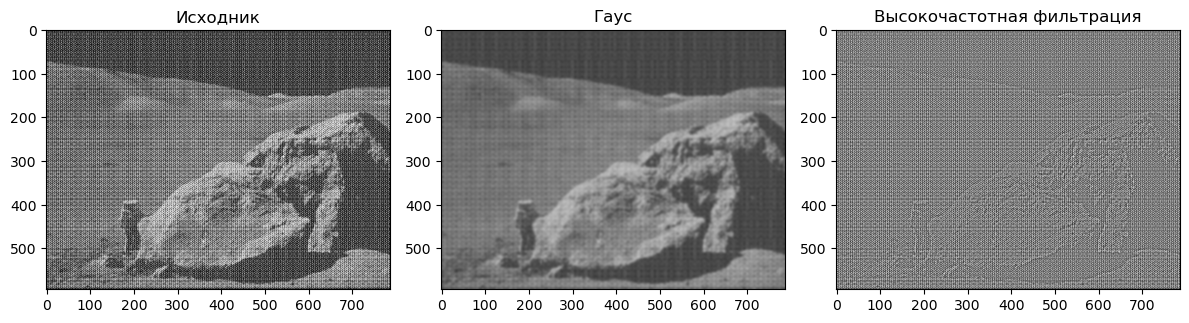

In [19]:
image_float = image.astype(np.float32)

gaussian = cv2.GaussianBlur(image_float, (15, 15), 0)

high_freq = image_float - gaussian

high_freq_display = np.clip(high_freq + 128, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходник')

plt.subplot(1, 3, 2)
plt.imshow(gaussian, cmap='gray', vmin=0, vmax=255)
plt.title('Гаус')

plt.subplot(1, 3, 3)
plt.imshow(high_freq_display, cmap='gray', vmin=0, vmax=255)
plt.title('Высокочастотная фильтрация')

plt.tight_layout()
plt.show()

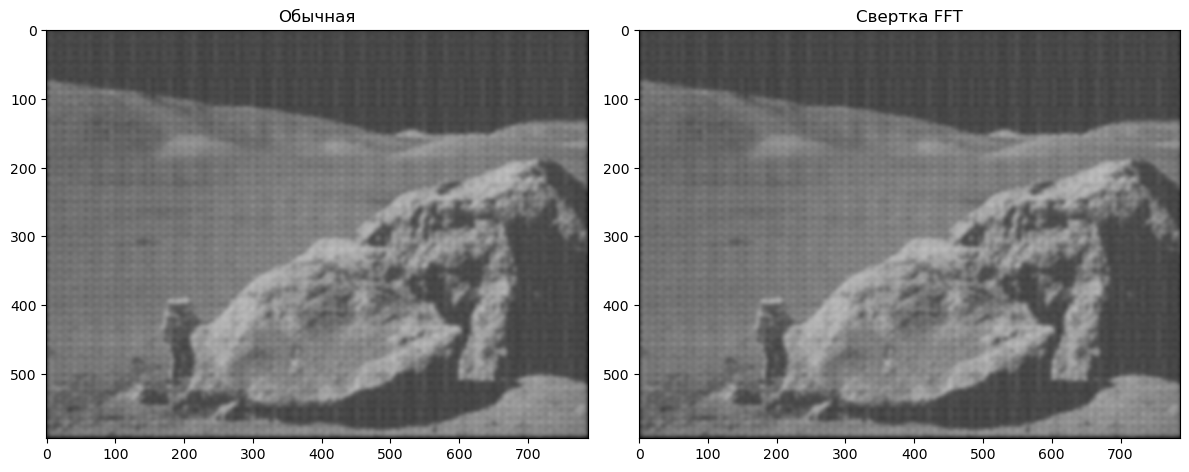

MSE между результатами: 0.0


In [20]:
kernel = cv2.getGaussianKernel(15, 3)
kernel_2d = kernel @ kernel.T

spatial_result = cv2.filter2D(
    image_float, -1, kernel_2d,
    borderType=cv2.BORDER_CONSTANT
)

fft_height = image.shape[0] + kernel_2d.shape[0] - 1
fft_width = image.shape[1] + kernel_2d.shape[1] - 1

image_fft = np.fft.fft2(image_float, s=(fft_height, fft_width))
kernel_fft = np.fft.fft2(kernel_2d, s=(fft_height, fft_width))

convolved = np.fft.ifft2(image_fft * kernel_fft).real

offset = kernel_2d.shape[0] // 2
fft_result = convolved[
    offset:offset + image.shape[0],
    offset:offset + image.shape[1]
]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(spatial_result, cmap='gray', vmin=0, vmax=255)
plt.title('Обычная')

plt.subplot(1, 2, 2)
plt.imshow(fft_result, cmap='gray', vmin=0, vmax=255)
plt.title('Свертка FFT')

plt.tight_layout()
plt.show()

mse = np.mean((spatial_result - fft_result) ** 2)
print('MSE между результатами:', round(mse, 6))

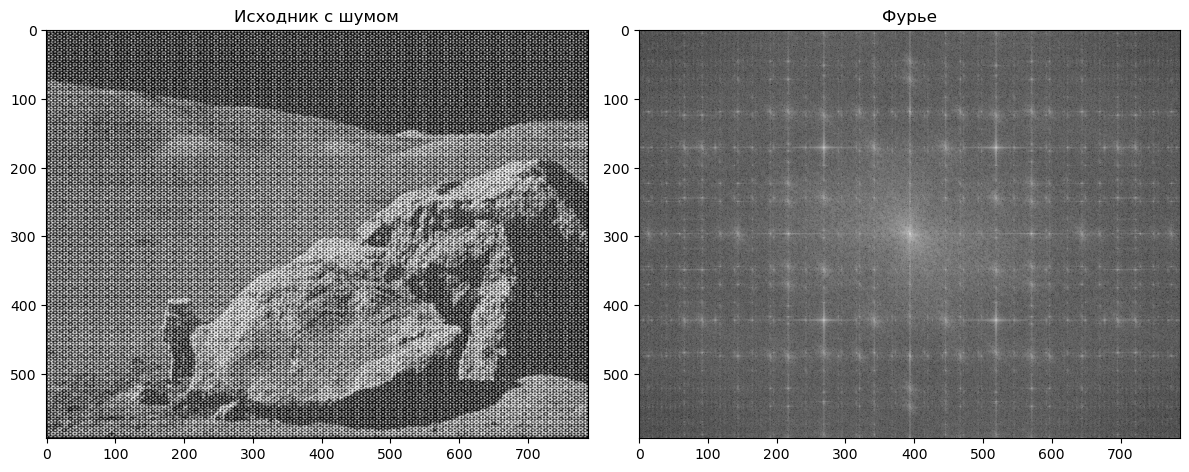

In [21]:
fft_image = np.fft.fft2(image_float)

fft_shifted = np.fft.fftshift(fft_image)

magnitude_spectrum = np.log1p(np.abs(fft_shifted))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходник с шумом')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Фурье')

plt.tight_layout()
plt.show()

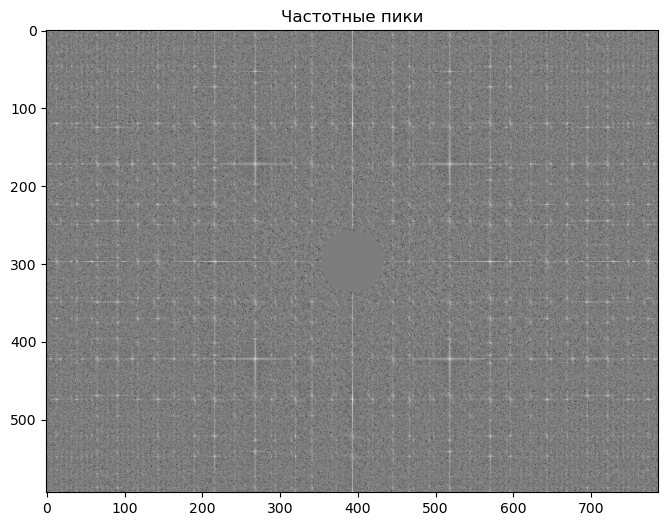

In [22]:
spectrum = np.log1p(np.abs(fft_shifted))

height, width = spectrum.shape
center_y, center_x = height // 2, width // 2

background = cv2.GaussianBlur(
    spectrum.astype(np.float32), (31, 31), 0
)

peaks = spectrum - background

yy, xx = np.ogrid[:height, :width]
center_mask = (xx - center_x)**2 + (yy - center_y)**2 > 40**2

peaks[~center_mask] = 0

plt.figure(figsize=(10, 6))
plt.imshow(peaks, cmap='gray')
plt.title('Частотные пики')
plt.show()


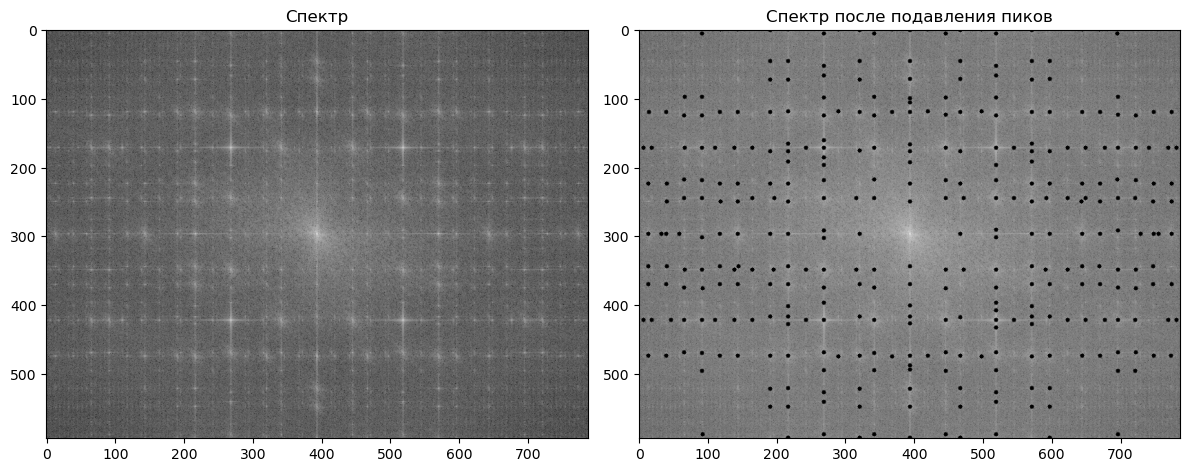

Обнаружено пиков: 333


In [24]:
filter_mask = np.ones((height, width), dtype=np.float32)

peaks_smooth = cv2.GaussianBlur(
    peaks.astype(np.float32), (3, 3), 0
)

local_max = cv2.dilate(
    peaks_smooth, np.ones((9, 9), np.uint8)
)

peak_threshold = 1.5

peak_points = (
    (peaks_smooth == local_max) &
    (peaks_smooth > peak_threshold) &
    center_mask
)

ys, xs = np.where(peak_points)

radius = 3

for y, x in zip(ys, xs):
    cv2.circle(filter_mask, (int(x), int(y)), radius, 0, -1)

    sym_y = (2 * center_y - y) % height
    sym_x = (2 * center_x - x) % width

    cv2.circle(
        filter_mask, (int(sym_x), int(sym_y)), radius, 0, -1
    )

filtered_fft = fft_shifted * filter_mask
filtered_spectrum = np.log1p(np.abs(filtered_fft))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Спектр')

plt.subplot(1, 2, 2)
plt.imshow(filtered_spectrum, cmap='gray')
plt.title('Спектр после подавления пиков')

plt.tight_layout()
plt.show()

print('Обнаружено пиков:', len(xs))


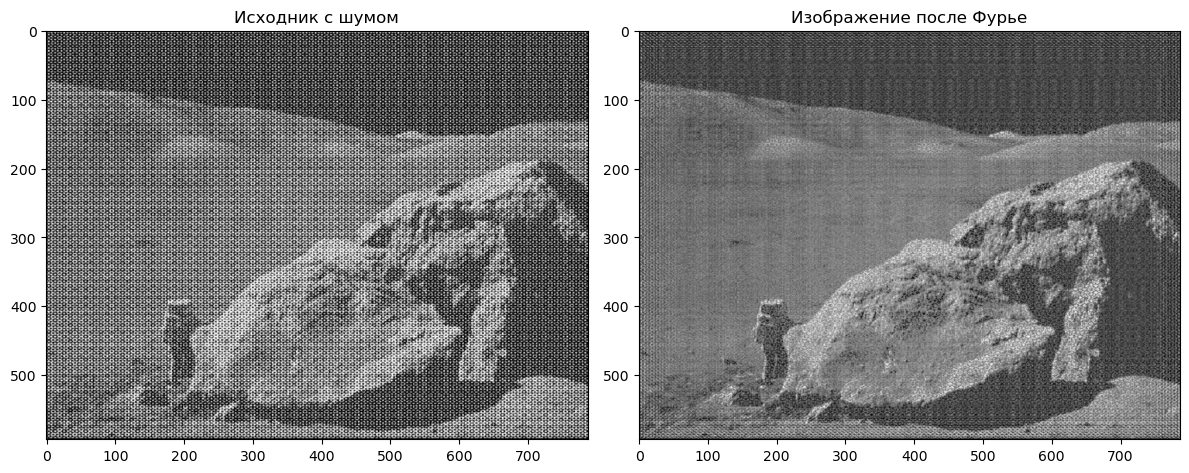

In [25]:
fft_restored = np.fft.ifftshift(filtered_fft)

image_restored = np.fft.ifft2(fft_restored).real

image_restored = np.clip(image_restored, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходник с шумом')

plt.subplot(1, 2, 2)
plt.imshow(image_restored, cmap='gray', vmin=0, vmax=255)
plt.title('Изображение после Фурье')

plt.tight_layout()
plt.show()